## Data Preparation

## Set up dataloaders

In [1]:
import os
import cv2
import torch
import numpy as np
from torch.utils.data import Dataset

class LimitedFOVDataset(Dataset):
    def __init__(self,
                 root_dir,
                 split='train',
                 pre_seq_length=30,
                 aft_seq_length=5,
                 suffix='.mp4',
                 frame_size=256):
        
        self.pre_seq_length = pre_seq_length
        self.aft_seq_length = aft_seq_length
        self.total_frames = pre_seq_length + aft_seq_length
        self.frame_size = frame_size

        self.mean = None
        self.std = None
        self.data_name = "limited-fov"
        
        self.folder = os.path.join(root_dir, split)
        self.video_paths = [
            os.path.join(self.folder, f)
            for f in os.listdir(self.folder)
            if f.endswith(suffix)
        ]

    def __len__(self):
        return len(self.video_paths)

    def _sample_frames(self, video_path):
        video = cv2.VideoCapture(video_path)
        total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))

        frame_idxs = np.linspace(
            0, total_frames - 1,
            self.total_frames,
            dtype=int
        )

        frames = []

        for idx in frame_idxs:
            video.set(cv2.CAP_PROP_POS_FRAMES, idx)
            ret, frame = video.read()
            if not ret:
                continue

            frame = cv2.resize(frame, (self.frame_size, self.frame_size))

            frames.append(frame)

        video.release()

        frames = np.stack(frames).transpose(0, 3, 1, 2) # (T, H, W, C) to 
        return frames

    def __getitem__(self, idx):
        video_path = self.video_paths[idx]

        frames = self._sample_frames(video_path)

        # Convert to tensor
        frames = torch.from_numpy(frames).float() / 255.0  # normalize

        x = frames[:self.pre_seq_length]
        y = frames[self.pre_seq_length:]

        selected_indices = np.linspace(0, self.pre_seq_length - 1, 17, dtype=int)
        x = x[selected_indices]

        return x, y

In [2]:
from torch.utils.data import DataLoader

batch_size = 1
num_workers = 1 # increase if CPU allows

root_dir = '/mnt/active_storage/Knut/LimitedFOVData/final_data_color/'

pre_seq_length = 30
aft_seq_length = 5
frame_size = 256

train_dataset = LimitedFOVDataset(
    root_dir=root_dir,
    split='train',
    pre_seq_length=pre_seq_length,
    aft_seq_length=aft_seq_length,
    frame_size=frame_size
)

val_dataset = LimitedFOVDataset(
    root_dir=root_dir,
    split='val',
    pre_seq_length=pre_seq_length,
    aft_seq_length=aft_seq_length,
    frame_size=frame_size
)

test_dataset = LimitedFOVDataset(
    root_dir=root_dir,
    split='test',
    pre_seq_length=pre_seq_length,
    aft_seq_length=aft_seq_length,
    frame_size=frame_size
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True
)

(17, 3, 256, 256)


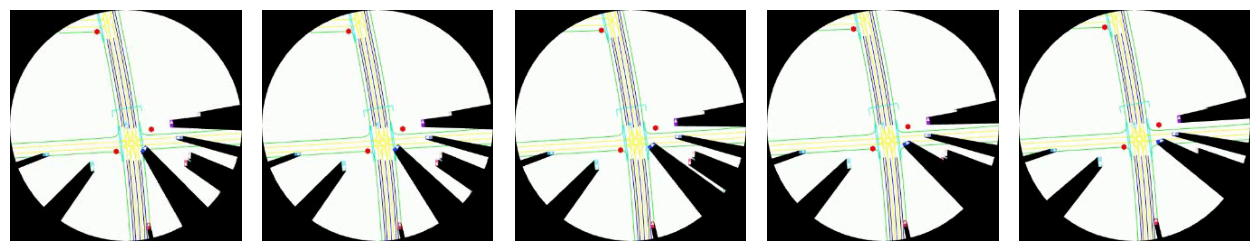

In [3]:
from openstl.utils import show_video_line

train_x, train_y = train_loader.dataset[0]

train_x = train_x.numpy()

# show some input frames from an example
example_idx = 0
print(train_x.shape)
show_video_line(train_x, ncols=5, vmax=0.6, cbar=False, out_path=None, format='png', use_rgb=True)

## Train and evaluate

In [5]:
exp_name = 'simvp_10ep_17color' #'simvp_10ep_color'

feature_img_length = 17

custom_training_config = {
    'pre_seq_length': feature_img_length,
    'aft_seq_length': aft_seq_length,
    'total_length': feature_img_length + aft_seq_length,
    'batch_size': batch_size,
    'val_batch_size': batch_size,
    'epoch': 10,
    'lr': 0.001,   
    'metrics': ['mse', 'mae', 'ssim'],
    'ex_name': exp_name,
    'dataname': 'custom',
    'in_shape': [feature_img_length, 3, frame_size, frame_size],
    'gpus': [1]
}

custom_model_config = { # SimVPv2 model config
    'method': 'SimVP',
    'spatio_kernel_enc': 3,
    'spation_kernel_dec': 3,
    'model_type': 'gSTA',
    'N_S': 4,
    'N_T': 8,
    'hid_S': 64,
    'hid_T': 512
}

# custom_model_config = { # TAU model config
#     'method': 'TAU',
#     'spatio_kernel_enc': 3,
#     'spatio_kernel_dec': 3,
#     'model_type': 'tau',
#     'hid_S': 64,
#     'hid_T': 512,
#     'N_T': 8,
#     'N_S': 4,
#     'alpha': 0.1,
#     'drop_path': 0,
# }


In [6]:
from openstl.api import BaseExperiment
from openstl.utils import create_parser, default_parser

args = create_parser().parse_args([])
config = args.__dict__

# update the training config
config.update(custom_training_config)
# update the model config
config.update(custom_model_config)
# fulfill with default values
default_values = default_parser()
for attribute in default_values.keys():
    if config[attribute] is None:
        config[attribute] = default_values[attribute]



In [7]:

# train model
exp = BaseExperiment(args, dataloaders=(train_loader, val_loader, test_loader), strategy='auto')
print('>'*35 + ' training ' + '<'*35)
exp.train()


In [8]:

# re-define training config with test=true and fps=True to get fps, FLOPS along with other metrics
custom_training_config = {
    'pre_seq_length': feature_img_length,
    'aft_seq_length': aft_seq_length,
    'total_length': feature_img_length + aft_seq_length,
    'batch_size': batch_size,
    'val_batch_size': batch_size,
    'epoch': 10,
    'lr': 0.001,   
    'metrics': ['mse', 'mae', 'ssim'],
    'ex_name': exp_name,
    'dataname': 'custom',
    'in_shape': [feature_img_length, 3, frame_size, frame_size],
    'gpus': [1],
    'test': True,
    'fps': True,
}

args = create_parser().parse_args([])
config = args.__dict__

# update the training config
config.update(custom_training_config)
# update the model config
config.update(custom_model_config)
# fulfill with default values
default_values = default_parser()
for attribute in default_values.keys():
    if config[attribute] is None:
        config[attribute] = default_values[attribute]

exp = BaseExperiment(args, dataloaders=(train_loader, val_loader, test_loader), strategy='auto')

print('>'*35 + ' testing  ' + '<'*35)
results = exp.test()


Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs


>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>> testing  <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<


You are using a CUDA device ('NVIDIA GeForce RTX 3090') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Testing: |          | 0/? [00:00<?, ?it/s]

test epoch end
results concatenated
mse:848.8653564453125, mae:4979.7294921875, ssim:0.8599417980372905


In [9]:
info, flops, fps, dash_line = exp.display_method_info(args)
print('FLOPS: ', flops, ' FPS: ', fps)

FLOPS:  | module                           | #parameters or shape   | #flops     |
|:---------------------------------|:-----------------------|:-----------|
| model                            | 62.791M                | 0.384T     |
|  enc.enc                         |  0.113M                |  25.584G   |
|   enc.enc.0.conv                 |   1.92K                |   2.282G   |
|    enc.enc.0.conv.conv           |    1.792K              |    1.925G  |
|    enc.enc.0.conv.norm           |    0.128K              |    0.357G  |
|   enc.enc.1.conv                 |   37.056K              |   10.357G  |
|    enc.enc.1.conv.conv           |    36.928K             |    10.268G |
|    enc.enc.1.conv.norm           |    0.128K              |    89.129M |
|   enc.enc.2.conv                 |   37.056K              |   10.357G  |
|    enc.enc.2.conv.conv           |    36.928K             |    10.268G |
|    enc.enc.2.conv.norm           |    0.128K              |    89.129M |
|   enc.enc.3.con

## Visualization

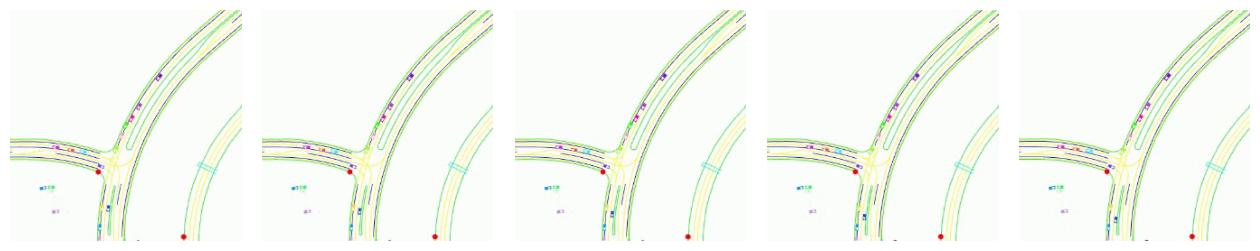

In [10]:
import numpy as np
from openstl.utils import show_video_line

# exp_name = 'tau_10ep_color'
# results.clear()

import gc
gc.collect()

# show the given frames from an example
inputs = np.load('./work_dirs/'+exp_name+'/saved/inputs.npy')
preds = np.load('./work_dirs/'+exp_name+'/saved/preds.npy')
trues = np.load('./work_dirs/'+exp_name+'/saved/trues.npy')

example_idx = 0
show_video_line(trues[example_idx], ncols=aft_seq_length, vmax=0.6, cbar=False, out_path=None, format='png', use_rgb=True)

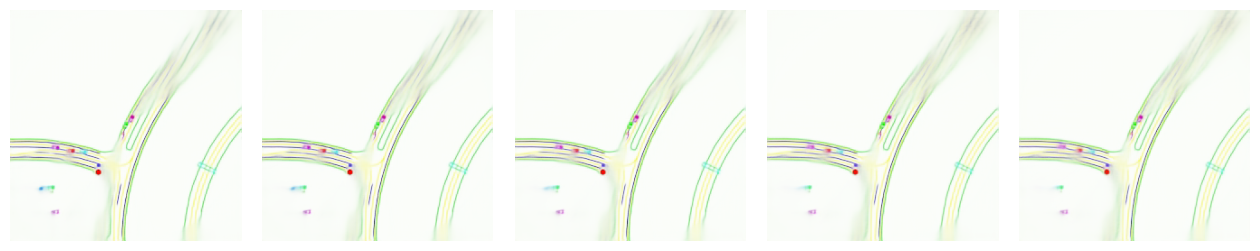

In [11]:
example_idx = 0
show_video_line(preds[example_idx], ncols=aft_seq_length, vmax=0.6, cbar=False, out_path=None, format='png', use_rgb=True)

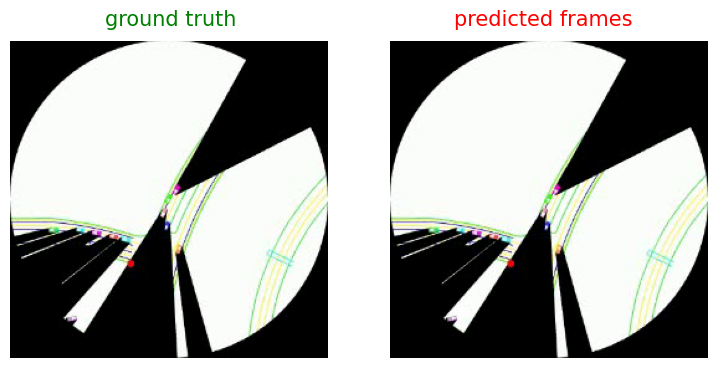

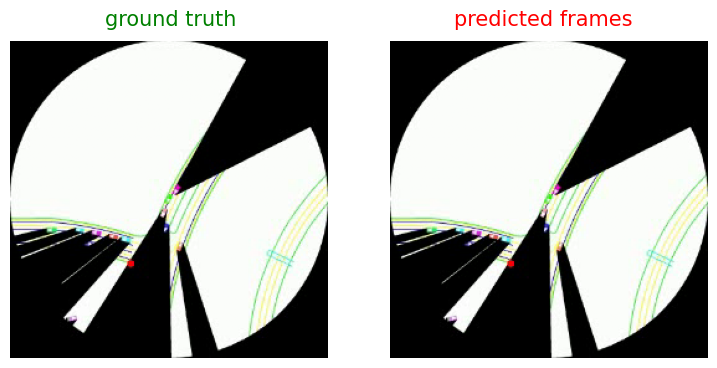

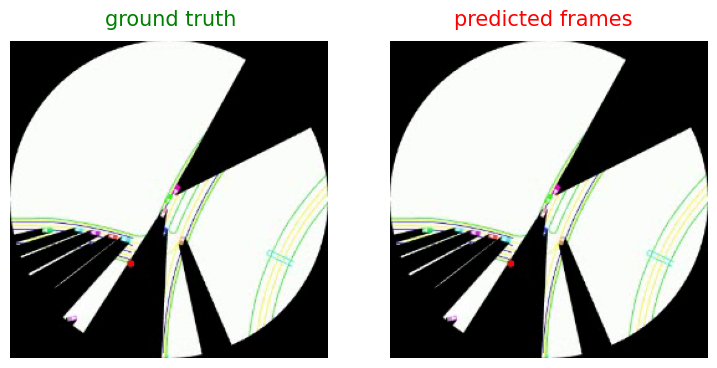

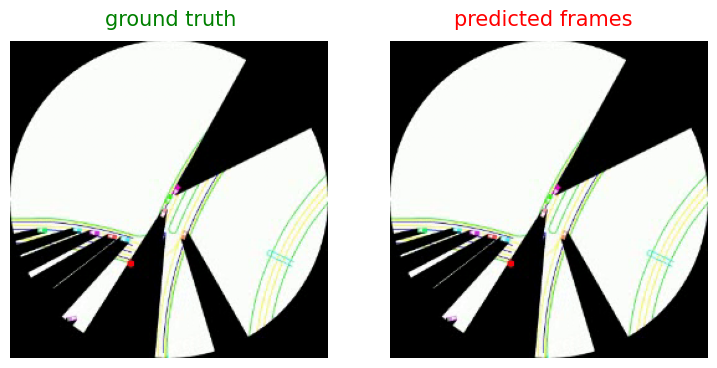

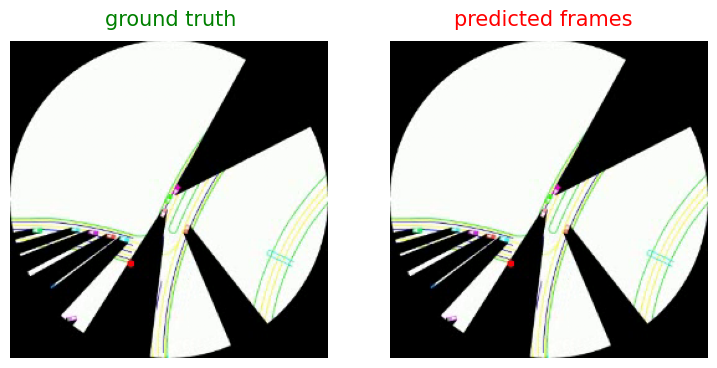

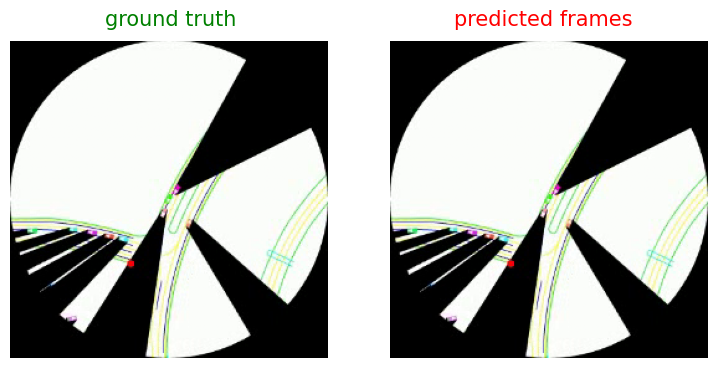

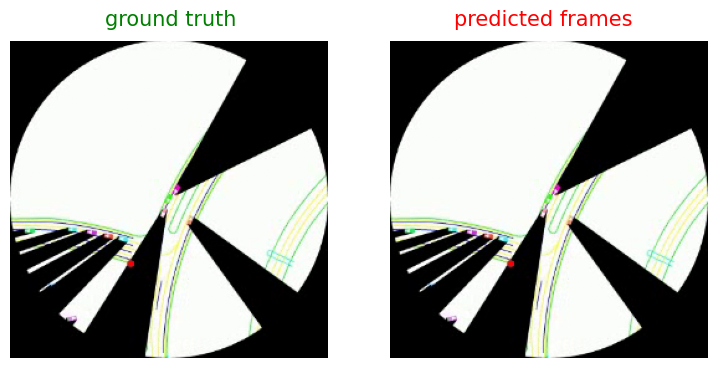

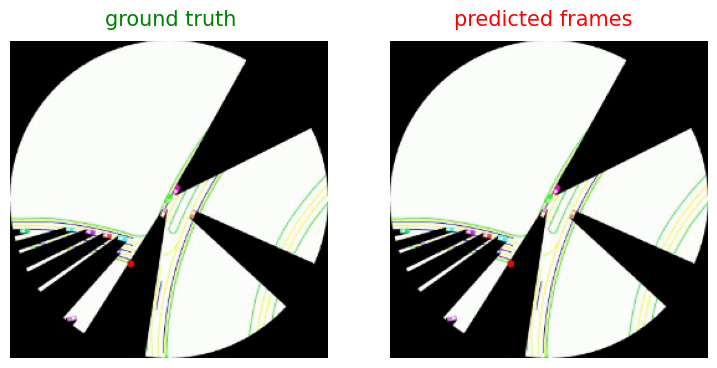

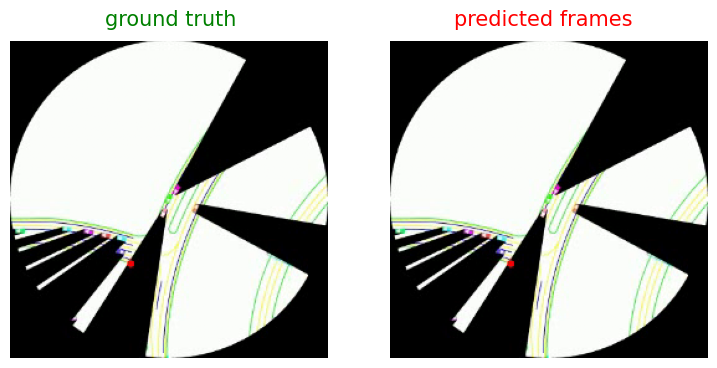

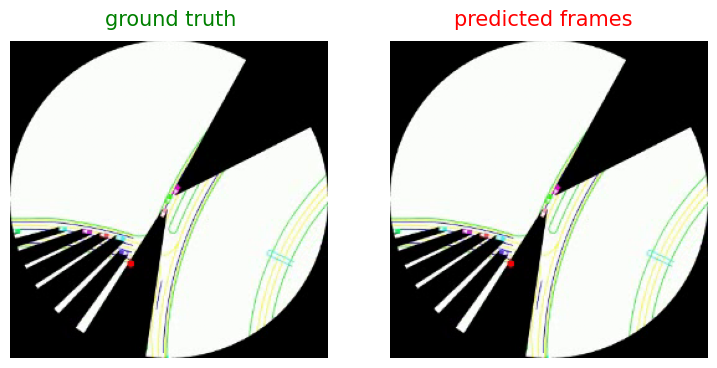

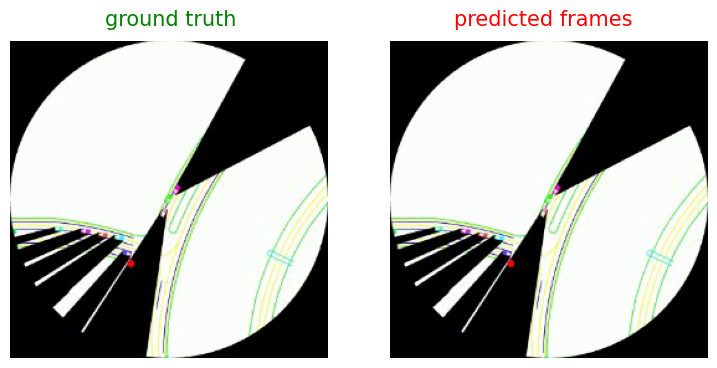

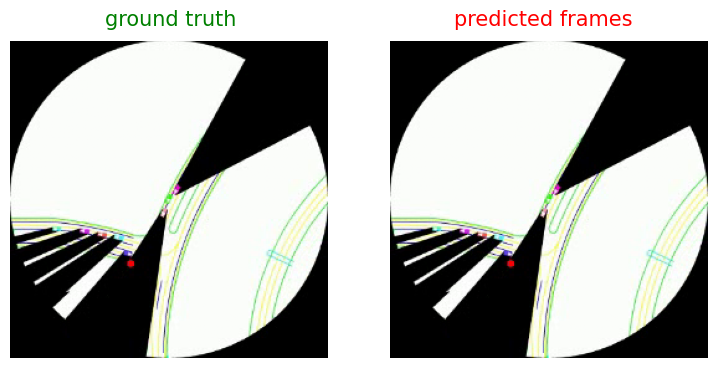

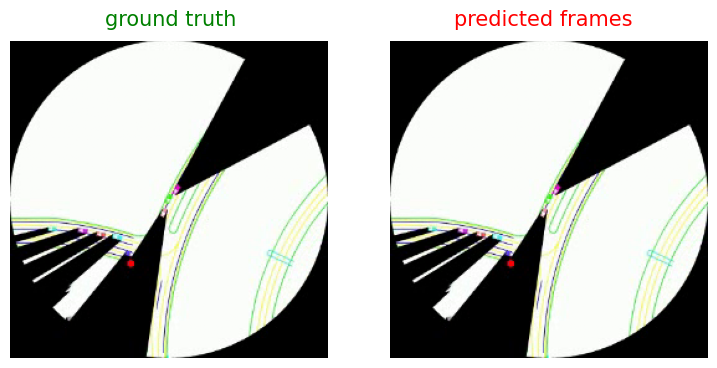

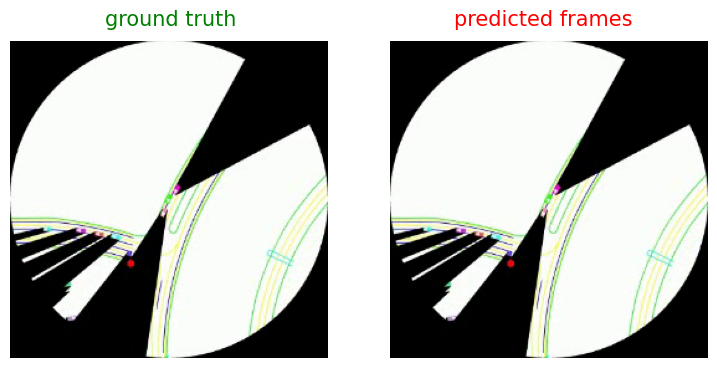

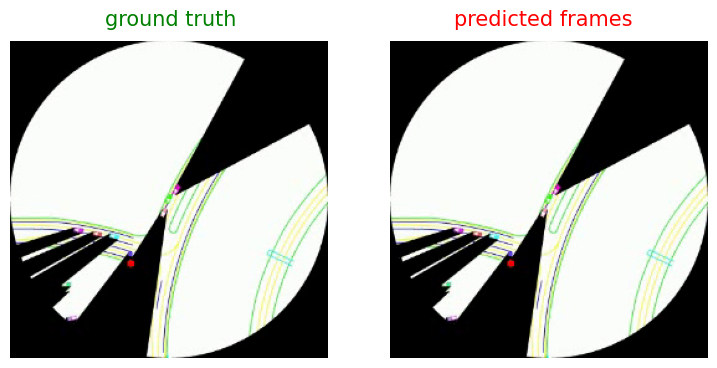

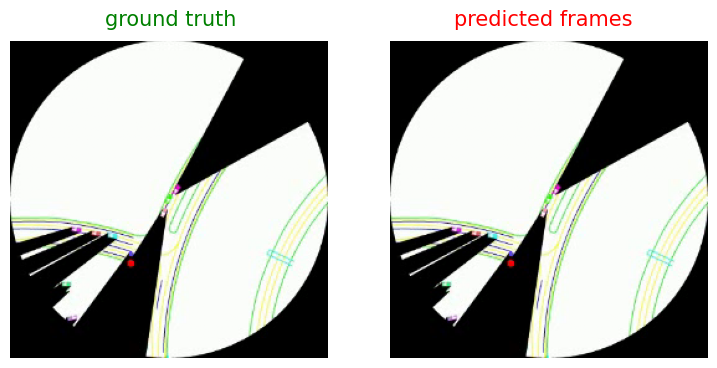

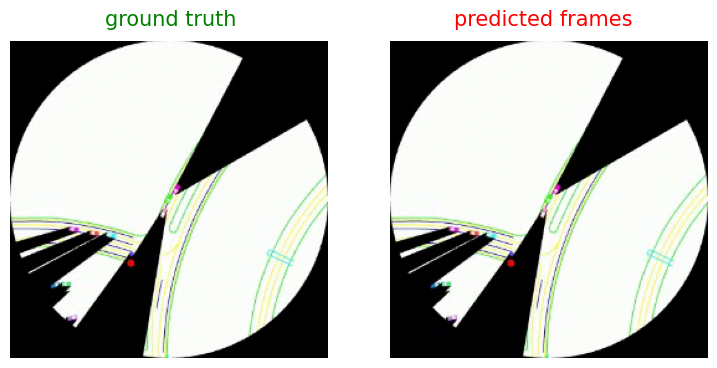

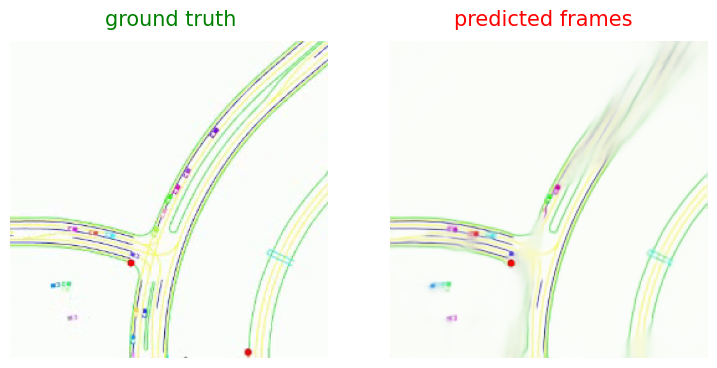

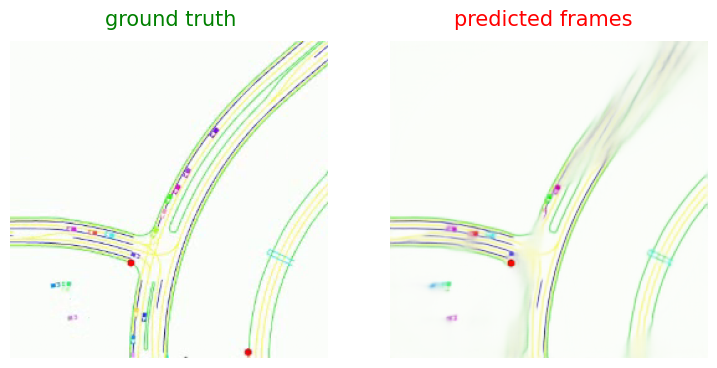

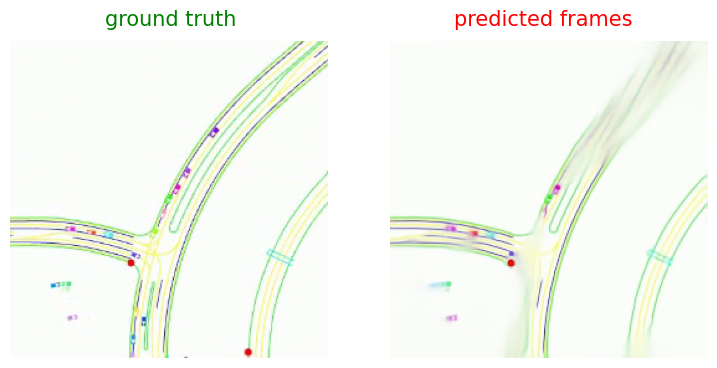

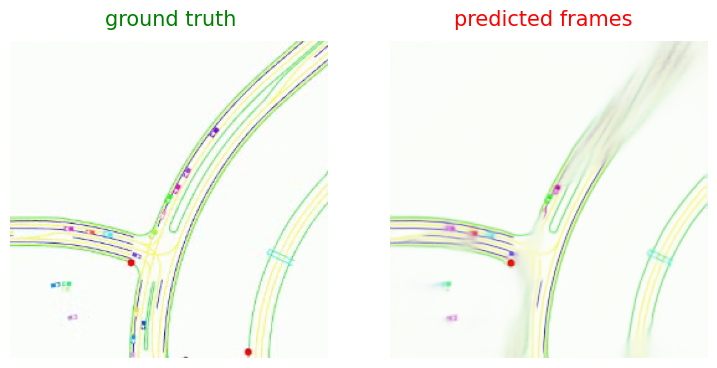

In [12]:
from openstl.utils import show_video_gif_multiple

example_idx = 0
show_video_gif_multiple(inputs[example_idx], trues[example_idx], preds[example_idx], use_rgb=True, out_path='example.gif')

In [13]:
# print(trues[example_idx])